# Health Study – Statistical Analysis

## Del 1 – Basic Analysis and Statistics

This project analyzes health study data using Python.

The analysis includes:
- Descriptive statistics
- Data visualization
- Disease simulation
- Confidence intervals
- Hypothesis testing
- Statistical power simulation

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

np.random.seed(42)



## 1. Data Loading

### Objective
Load the health study dataset and inspect its structure before starting the analysis.

### Method
The dataset is loaded using Pandas. Python's `pathlib` module is used to construct a relative file path, allowing the notebook to run from both the project root and the `notebooks` directory.


In [3]:
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_path = project_dir / "data" / "health_study_dataset.csv"

df = pd.read_csv(data_path)

df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0



### Initial Observation

The dataset was successfully loaded, and the first five rows were displayed to inspect the available variables.

The dataset contains demographic information, health measurements, smoking status, and disease status.

Further checks will be performed to examine the dataset's structure and data quality before the statistical analysis.



## 2. Data Exploration and Quality Checks

### Objective
Explore the structure and quality of the dataset before performing statistical analysis.

### Method
Pandas is used to inspect the dataset dimensions, data types, missing values, and duplicate records. Basic validity checks are also performed to identify potentially incorrect values.


In [4]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicated rows:", df.duplicated().sum())
print("Duplicated IDs:", df["id"].duplicated().sum())


Dataset shape: (800, 9)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB

Missing values:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Duplicated rows: 0
Duplicated IDs: 0


In [5]:
print("Invalid ages:", (df["age"] <= 0).sum())
print("Invalid heights:", (df["height"] <= 0).sum())
print("Invalid weights:", (df["weight"] <= 0).sum())
print("Invalid blood pressure:", (df["systolic_bp"] <= 0).sum())
print("Invalid cholesterol:", (df["cholesterol"] <= 0).sum())

print("\nSex values:", df["sex"].unique())
print("Smoker values:", df["smoker"].unique())
print("Disease values:", df["disease"].unique())


Invalid ages: 0
Invalid heights: 0
Invalid weights: 0
Invalid blood pressure: 0
Invalid cholesterol: 0

Sex values: <StringArray>
['F', 'M']
Length: 2, dtype: str
Smoker values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Disease values: [0 1]



### Results and Interpretation

The dataset contains 800 observations and 9 columns, including a unique participant ID.

The initial data quality checks showed:
- No missing values.
- No duplicated rows or participant IDs.
- No zero or negative values in age, height, weight, systolic blood pressure, or cholesterol.
- Expected categories for sex (F/M), smoking status (Yes/No), and disease status (0/1).

Based on these checks, no immediate data cleaning is required before the statistical analysis.

However, potential outliers and unusual values will be explored during the descriptive analysis and visualization stages.



## 3. Descriptive Statistics

### Objective
Summarize the main characteristics of the numerical health variables using descriptive statistics.

### Method
Pandas is used to calculate the mean, median, minimum, and maximum values for age, weight, height, systolic blood pressure, and cholesterol.


In [6]:
numeric_cols = [
    "age",
    "weight",
    "height",
    "systolic_bp",
    "cholesterol"
]

descriptive_stats = df[numeric_cols].agg(
    ["mean", "median", "min", "max"]
).T

descriptive_stats = descriptive_stats.round(2)

descriptive_stats

,mean,median,min,max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88



### Results and Interpretation

The descriptive statistics show that the participants' mean age is 49.43 years, with ages ranging from 18 to 90 years.

The mean systolic blood pressure is 149.18 mmHg, while the median is 149.40 mmHg.

The mean and median values are relatively close across the numerical variables, suggesting limited differences between these two measures of central tendency.

However, descriptive statistics alone cannot fully describe the shape of the distributions or identify potential outliers. These aspects will be explored through visualizations in the next section.



## 4. Data Visualization

### Objective
Visualize the distributions and patterns in the health study data to complement the descriptive statistics.

### Method
Matplotlib and Seaborn are used to create three types of visualizations: a histogram, a boxplot, and a bar chart. Each visualization is selected according to the variables being analyzed.



### 4.1 Distribution of Systolic Blood Pressure

A histogram is used to examine the distribution of systolic blood pressure among participants, including its shape, concentration, and potential extreme values.


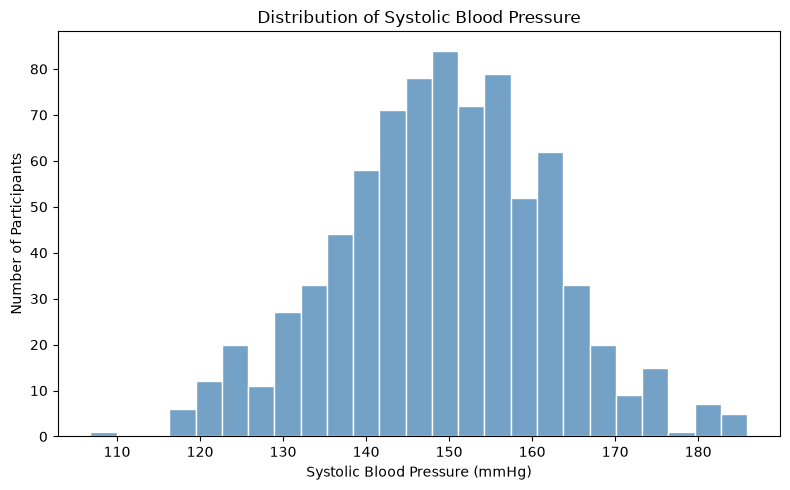

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="systolic_bp",
    bins=25,
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Systolic Blood Pressure")
plt.xlabel("Systolic Blood Pressure (mmHg)")
plt.ylabel("Number of Participants")

plt.tight_layout()
plt.show()


The distribution of systolic blood pressure appears approximately bell-shaped and fairly symmetric, with most values concentrated between 140 and 160 mmHg.

The mean (149.18 mmHg) and median (149.40 mmHg) are very close, suggesting no strong skewness in the distribution.

A few observations appear at the lower and upper ends of the distribution. However, the histogram alone is not sufficient to determine whether these values are statistical outliers.



### 4.2 Weight Distribution by Sex

A boxplot is used to compare the distribution of weight between male and female participants, focusing on the median, spread, and potential outliers.


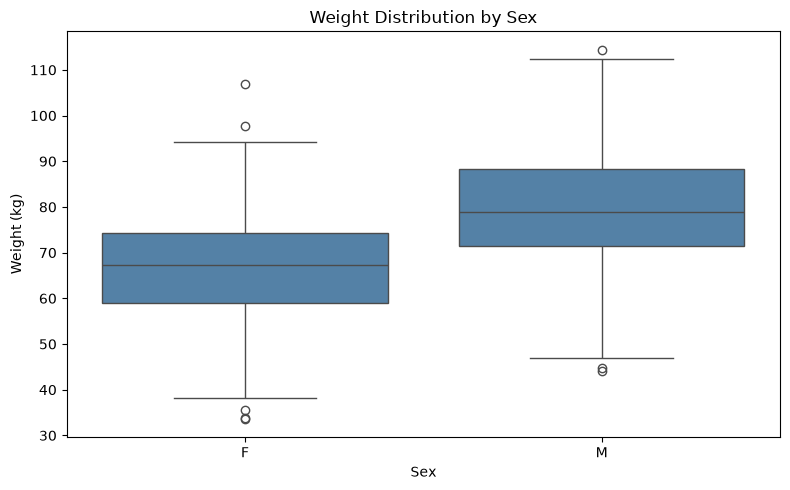

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="weight",
    order=["F", "M"],
    color="steelblue"
)

plt.title("Weight Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Weight (kg)")

plt.tight_layout()
plt.show()



#### Results and Interpretation

The boxplot shows that male participants generally have higher weights than female participants, with an estimated median of approximately 79 kg for males and 67 kg for females.

The interquartile ranges (IQRs) appear relatively similar between the two groups, suggesting comparable variability in the middle 50% of the weight distributions.

Several potential outliers are visible in both groups. These values are not necessarily data errors and should not be removed without further investigation.

The observed differences are descriptive and do not establish a statistically significant difference or a causal relationship.



### 4.3 Smoking Status Distribution

A bar chart is used to visualize the proportion of smokers and non-smokers in the dataset.


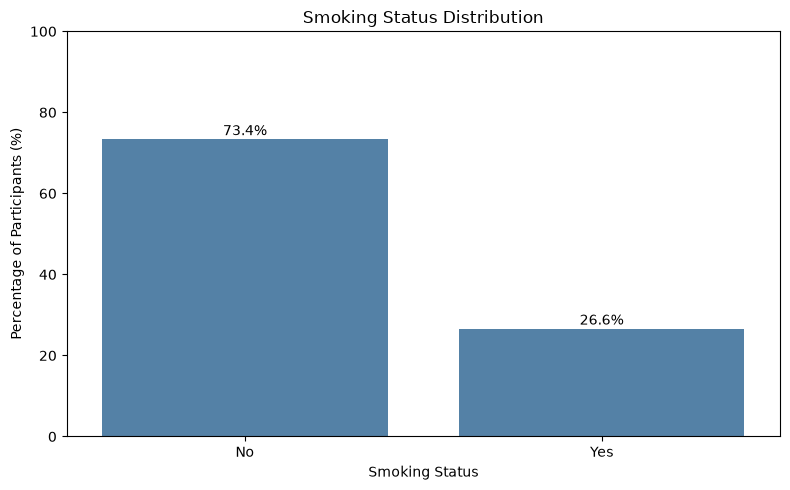

In [9]:
smoking_pct = (
    df["smoker"]
    .value_counts(normalize=True)
    .mul(100)
    .reindex(["No", "Yes"])
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=smoking_pct.index,
    y=smoking_pct.values,
    color="steelblue"
)

for i, value in enumerate(smoking_pct.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.title("Smoking Status Distribution")
plt.xlabel("Smoking Status")
plt.ylabel("Percentage of Participants (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()



#### Results and Interpretation

The bar chart shows that 73.4% of participants are non-smokers, while 26.6% are smokers.

The two groups differ in size, with 587 non-smokers and 213 smokers.

This imbalance is relevant for the upcoming hypothesis test comparing mean systolic blood pressure between smokers and non-smokers.

However, this chart only describes smoking status and does not provide evidence of a relationship between smoking and blood pressure.


## 5. Disease Simulation

### Objective
Estimate the proportion of participants with the disease and simulate disease occurrence among 1,000 individuals using the observed disease probability.

### Method
The observed disease proportion is calculated from the dataset. NumPy's binomial distribution is then used to simulate binary disease outcomes (0 or 1), assuming the same probability of disease for each individual.

A fixed random seed is used to ensure reproducibility.


In [10]:
disease_rate = df["disease"].mean()

simulated_disease = np.random.binomial(
    n=1,
    p=disease_rate,
    size=1000
)

simulated_rate = simulated_disease.mean()

print(f"Observed disease rate: {disease_rate:.2%}")
print(f"Simulated disease rate: {simulated_rate:.2%}")
print(f"Difference: {simulated_rate - disease_rate:.2%}")


Observed disease rate: 5.88%
Simulated disease rate: 5.60%
Difference: -0.27%



### Results and Interpretation

The observed disease proportion in the dataset is 5.88%, while the simulated proportion among 1,000 individuals is 5.60%.

The simulated proportion is approximately 0.28 percentage points lower than the observed proportion.

This small difference is expected due to random variation. Even when the same probability is used, the number of disease cases can vary between simulations.

The simulation assumes that all individuals have the same probability of disease and that their outcomes are independent. It does not account for individual characteristics such as age, smoking status, or cholesterol level.
